# One dataset, many algorithms: statistics and computational complexity

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 04 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/04_Statistics_Algorithms_and_Complexity.ipynb)

**Case study · Python · engineering measurements**

Analyze a list of 20 synthetic temperature measurements. Begin with readable
loops, compare algorithms that calculate the same statistic, and explain the
cost in both time and memory.

**Core path:** roughly 75–90 minutes. Quickselect and the numerical-accuracy
experiment are extensions for a second sitting.

The notebook is self-contained: upload it to Google Colab or open it in Jupyter
and run its cells from top to bottom. The main calculations use Python's standard
library. Matplotlib is used only for the two figures; it is normally available
in Colab. No external datasets or downloads are needed.

By the end, students should be able to:

1. Calculate and interpret mean, median, modes, range, and sample variance.
2. Recognize loops hidden inside helper calls and library functions.
3. Distinguish sequential scans from nested scans.
4. Compare sorting with selection for computing a median.
5. Explain the extra memory used by dictionaries and copied lists.
6. Distinguish mathematical equivalence, numerical accuracy, and execution time.

**Predict before running:** Which statistic requires the data to be fully sorted?
Can we obtain a median without sorting every element? Does a function with one
visible `for` loop necessarily run in linear time?


<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Core · Part 2, Collections and data |
| **Time** | about 75–90 min |
| **Before this** | Notebooks 01–03: loops, functions, lists and dictionaries. |
| **Essential** | Sections 1–6, 8, 9 and 12–16. |
| **Optional on a first reading** | The extensions in Sections 7, 10 and 11. For more depth: the extended edition, notebook 18. |
| **Next** | 05, where NumPy arrays replace lists. |

**You have understood this notebook if you can, without looking back:**

1. Compute the mean, minimum and maximum in one loop, and say why that costs O(n).
2. Explain why finding a mode with nested loops costs O(n²), while a dictionary of counts costs O(n).
3. Compare insertion sort with merge sort, and say which median method you would use for a million readings, and why.
4. Compute quartiles, the IQR and Tukey's fences, and explain why the 40 °C reading is flagged rather than deleted.
5. Read a log–log timing plot: its slope estimates the exponent k in O(nᵏ).

**Not expected of you:** Proving complexity bounds; memorising the code of quickselect.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## 1. Meet the data

The values represent integer-rounded temperature readings in degrees Celsius.
They are invented for teaching, not experimental results. Repeated values make
frequency counting meaningful, while the final reading provides a useful
contrast between the mean and median.

Our input contract is a finite list or tuple of real numbers. Missing values,
NaN, infinity, and nonnumeric entries require an explicit data-cleaning policy
and are rejected here. The small core functions assume this contract; we check
it once before using the data. Do not use a coefficient of variation for Celsius
temperatures: the zero of that scale is arbitrary.


In [1]:
# Import math for square roots and finiteness checks.
import math
# Import random for seeded random choices (quickselect pivots, benchmark data).
import random
# Import statistics: the standard library's reference implementations.
import statistics
# Import timeit for timing small pieces of code.
import timeit
# Import Real, the abstract type that every real number type (int, float, ...) belongs to.
from numbers import Real

# Twenty synthetic temperature readings in °C; the 40 is a deliberate high value.
DATA = [
    21, 23, 25, 22, 24, 23, 26, 21, 24, 23,
    27, 22, 25, 24, 23, 28, 22, 24, 23, 40,
]

# Show the data.
print("Measurements (°C):", DATA)
# n = 20.
print("Number of measurements:", len(DATA))


Measurements (°C): [21, 23, 25, 22, 24, 23, 26, 21, 24, 23, 27, 22, 25, 24, 23, 28, 22, 24, 23, 40]
Number of measurements: 20


In [2]:
# Define a function that checks the input before any statistic is computed.
def validate_measurements(values, minimum_count=1):
    """Check a finite, numeric sequence without making another list."""
    # Too few values for the statistic that will follow?
    if len(values) < minimum_count:
        # Stop with a clear message.
        raise ValueError(f"At least {minimum_count} measurements are required.")
    # Inspect every value once: O(n).
    for value in values:
        # bool is a subclass of int in Python, so True/False are rejected explicitly.
        if isinstance(value, bool) or not isinstance(value, Real):
            # Stop with a clear message about the type.
            raise TypeError("Measurements must be real numbers, not booleans.")
        # NaN and infinity would make every statistic meaningless.
        if not math.isfinite(value):
            # Stop with a clear message.
            raise ValueError("Measurements must be finite; NaN is not supported.")


In [3]:
# Run the check; nothing happens if the data are valid.
validate_measurements(DATA, minimum_count=2)
# Reached only when no exception was raised.
print("The measurements satisfy the input contract.")


The measurements satisfy the input contract.


## 2. What does computational complexity describe?

Let $n$ be the number of measurements, and $u$ the number of distinct values.
For this lesson, treat arithmetic and comparisons on these ordinary numbers as
constant-cost operations. This model does not cover arbitrarily large integer
bit costs.

| Operation or pattern | Cost under this model | Reason |
|---|---:|---|
| `len(values)` for a Python list | $O(1)$ | Its length is stored |
| `values[i]` | $O(1)$ | Direct indexing |
| One complete scan | $O(n)$ | Visit each item once |
| Two consecutive complete scans | $O(n)$ | $n+n=2n$ |
| A full scan inside every iteration of a full scan | $O(n^2)$ | $n\times n$ visits |
| A dictionary lookup or update | Expected amortized $O(1)$ | Assumes normal hash-table behavior |
| `values.count(x)` | $O(n)$ | Searches through the list |
| A list copy or full slice | $O(n)$ time and space | Copies the references |
| `sorted(values)` | $O(n\log n)$ worst-case time | Produces an ordered copy |

Big-O describes growth rather than an exact time in seconds. Worst-case,
average-case, and expected-over-random-choices are different claims. Python's
built-in sorting also adapts to existing order; its worst-case bound does not
mean every input takes the same amount of work.

**Space convention:** count additional working storage beyond the existing input.
State separately when a result list itself needs $O(n)$ memory.


## 3. Mean, minimum, maximum, and range: scan instead of sort

For measurements $x_1,\ldots,x_n$, the arithmetic mean is

$$\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i.$$

A running total is sufficient. The mean needs neither sorting nor a nested loop.
Likewise, keep the smallest and largest values seen so far in a single scan.


In [4]:
# Define the mean computed in a single pass over the data.
def mean_one_pass(values):
    """O(n) time; O(1) extra space. Assume a nonempty numeric sequence."""
    # An empty list has no mean.
    if not values:
        # Stop with a clear message.
        raise ValueError("The mean requires at least one value.")
    # Running sum, starting at zero.
    total = 0.0
    # Visit each value once.
    for value in values:
        # Add it to the running sum.
        total += value
    # Mean = sum / count.
    return total / len(values)

# Define a function that finds the minimum and maximum in the same single pass.
def extrema_one_pass(values):
    """Find minimum and maximum together: O(n) time, O(1) extra space."""
    # An empty list has no extrema.
    if not values:
        # Stop with a clear message.
        raise ValueError("Extrema require at least one value.")
    # An iterator lets us take the first value and then continue from the second.
    iterator = iter(values)
    # The first value starts as both the smallest and the largest.
    smallest = largest = next(iterator)
    # Visit each remaining value once.
    for value in iterator:
        # New smallest value?
        if value < smallest:
            # Update it.
            smallest = value
        # New largest value? (a separate if, because one value can't be both)
        if value > largest:
            # Update it.
            largest = value
    # Return both as a tuple.
    return smallest, largest


In [5]:
# Compute the mean.
mean = mean_one_pass(DATA)
# Unpack the returned tuple into two names.
minimum, maximum = extrema_one_pass(DATA)

# Print the mean to 2 decimals.
print(f"Mean:    {mean:.2f} °C")
# Print the minimum.
print(f"Minimum: {minimum:.2f} °C")
# Print the maximum.
print(f"Maximum: {maximum:.2f} °C")
# Range = maximum - minimum.
print(f"Range:   {maximum - minimum:.2f} °C")


Mean:    24.50 °C
Minimum: 21.00 °C
Maximum: 40.00 °C
Range:   19.00 °C


Both algorithms take **O(n) time and O(1) extra space**. The extrema loop uses
two comparisons for each value after the first: exactly `2 * (n - 1)` comparisons
in this version. A paired-comparison algorithm can reduce that constant without
changing the linear complexity class.

**Discuss:** Sorting first would let us read the minimum and maximum at the ends.
Why is that unnecessary if those are the only two answers we need?


## 4. Sample variance: two loops do not necessarily mean quadratic time

The sample variance and standard deviation are

$$s^2=\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}, \qquad s=\sqrt{s^2}.$$

Use $n-1$ for the sample variance in this lesson. If these readings are treated
as the entire population being described, use $n$ instead. Variance has units
of °C², while standard deviation has units of °C.

Compare an inefficient version with a version that computes the mean once.


In [6]:
# Define a deliberately slow variance that recomputes the mean inside the loop.
def sample_variance_repeated_mean(values):
    """An intentionally inefficient O(n^2) algorithm; O(1) extra space."""
    # The sample variance needs at least two values.
    if len(values) < 2:
        # Stop with a clear message.
        raise ValueError("Sample variance requires at least two values.")
    # Running sum of squared deviations.
    squared_deviations = 0.0
    # n outer iterations ...
    for value in values:
        # This helper scans the ENTIRE input on EVERY outer iteration.
        squared_deviations += (value - mean_one_pass(values)) ** 2
    # Divide by n - 1 for the sample variance.
    return squared_deviations / (len(values) - 1)

# Define the efficient version: compute the mean once, then the deviations.
def sample_variance_two_pass(values):
    """O(n) time, O(1) extra space: compute the mean once, then deviations."""
    # The sample variance needs at least two values.
    if len(values) < 2:
        # Stop with a clear message.
        raise ValueError("Sample variance requires at least two values.")
    # First pass: the mean, computed once.
    mean = mean_one_pass(values)
    # Running sum of squared deviations.
    squared_deviations = 0.0
    # Second pass over the data.
    for value in values:
        # Add this value's squared deviation.
        squared_deviations += (value - mean) ** 2
    # Divide by n - 1.
    return squared_deviations / (len(values) - 1)


In [7]:
# O(n²) version.
slow_variance = sample_variance_repeated_mean(DATA)
# O(n) version.
fast_variance = sample_variance_two_pass(DATA)

# Print the slow result.
print(f"Repeated-mean sample variance: {slow_variance:.6f} °C²")
# Print the fast result: the same number.
print(f"Two-pass sample variance:      {fast_variance:.6f} °C²")
# Standard deviation = sqrt(variance).
print(f"Sample standard deviation:     {math.sqrt(fast_variance):.6f} °C")
# math.isclose allows for tiny round-off differences.
print("Numerically equal here:", math.isclose(slow_variance, fast_variance))


Repeated-mean sample variance: 16.684211 °C²
Two-pass sample variance:      16.684211 °C²
Sample standard deviation:     4.084631 °C
Numerically equal here: True


In `sample_variance_repeated_mean`, the outer loop runs $n$ times, and its helper
scans all $n$ values each time: **$O(n^2)$**. There is only one visible loop in
that function, but the helper contains another scan.

In `sample_variance_two_pass`, one scan finds the mean and a second scan sums
the squared deviations: **$O(n)+O(n)=O(n)$**. Both versions use **$O(1)$ extra
space** because neither stores all the deviations.

**Ask students:** If the dataset grows from 100 to 200 readings, predict the
change in work for each method before measuring it.


## 5. Frequency and mode: nested scans versus a dictionary

The mode is a value with the largest frequency. There can be several tied
modes, so return all of them rather than silently choosing one. If every value
occurs once, this convention returns every value; it does not imply a useful
single dominant peak.

In the first algorithm, count matches for every candidate by scanning the
entire list. In the second, update one dictionary entry per reading.


In [8]:
# Define a function that counts how often each value occurs.
def frequency_counts(values):
    """Expected O(n) time; O(u) extra space for u distinct values."""
    # Empty dictionary: value -> count.
    counts = {}
    # One pass over the data.
    for value in values:
        # get(value, 0) returns 0 the first time a value is seen; then add 1.
        counts[value] = counts.get(value, 0) + 1
    # Return the frequency table.
    return counts

# Define a slow mode finder that counts each candidate by scanning the whole list.
def modes_quadratic(values):
    """Return (all modes, largest frequency) using n^2 equality checks."""
    # An empty list has no mode.
    if not values:
        # Stop with a clear message.
        raise ValueError("Modes require at least one value.")
    # candidate -> its frequency.
    counts = {}
    # Outer loop: n candidates.
    for candidate in values:
        # Count for this candidate.
        frequency = 0
        # Inner loop: n comparisons per candidate, n² in total.
        for value in values:
            # Equal to the candidate?
            if value == candidate:
                # Count it.
                frequency += 1
        # Store the frequency (repeated candidates are simply overwritten).
        counts[candidate] = frequency
    # The highest frequency.
    largest_frequency = max(counts.values())
    # Every value with that frequency (there may be ties).
    modes = [value for value, count in counts.items()
             if count == largest_frequency]
    # Return the modes and their frequency.
    return modes, largest_frequency

# Define a function that extracts the modes from an existing frequency table.
def modes_from_counts(counts):
    """Extract all tied modes in O(u) time from an existing frequency table."""
    # An empty table has no mode.
    if not counts:
        # Stop with a clear message.
        raise ValueError("Modes require at least one value.")
    # The highest frequency.
    largest_frequency = max(counts.values())
    # All values that reach it.
    modes = [value for value, count in counts.items()
             if count == largest_frequency]
    # Return the modes and their frequency.
    return modes, largest_frequency

# Define the fast mode finder: count in one pass, then extract.
def modes_hash(values):
    """Expected O(n) time and O(u) extra space, including the count table."""
    # Combine the two O(n)/O(u) steps.
    return modes_from_counts(frequency_counts(values))


In [9]:
# Build the frequency table.
counts = frequency_counts(DATA)
# Print it sorted by value for easy reading.
print("Frequency table:", dict(sorted(counts.items())))
# The slow method.
print("Nested scans (modes, frequency):", modes_quadratic(DATA))
# The fast method: the same answer.
print("Dictionary   (modes, frequency):", modes_hash(DATA))
# A tied example: both 1 and 2 are modes.
print("Tied example:", modes_hash([1, 1, 2, 2, 3]))


Frequency table: {21: 2, 22: 3, 23: 5, 24: 4, 25: 2, 26: 1, 27: 1, 28: 1, 40: 1}
Nested scans (modes, frequency): ([23], 5)
Dictionary   (modes, frequency): ([23], 5)
Tied example: ([1, 2], 2)


The nested version executes **exactly $n^2$ equality checks**, even when candidates
repeat. It uses $O(u)$ memory for the count dictionary. Writing
`values.count(candidate)` inside the outer loop would hide the inner scan without
removing it.

The dictionary version takes **expected $O(n)$ time and $O(u)$ extra space**:
one pass builds counts, and $O(u)$ additional work finds the modes. Here $u\le n$.
This expectation assumes ordinary hashing; pathological collisions can worsen
dictionary operations.

Sorting the frequency table merely to display its keys, as above, adds
$O(u\log u)$ display work. That sorting is not needed to calculate the mode.
For unrounded continuous measurements, exact repeated-value counts may be less
informative than a histogram with a stated bin width.


## 6. Median: first compare two sorting algorithms

The median is the middle ordered value for odd `n`, or the mean of the two
middle ordered values for even `n`. A median describes the center by rank.

**Insertion sort** grows a sorted prefix by shifting larger values to the right.
Its average and worst-case time are O(n²); already sorted input takes O(n).

**Merge sort** recursively sorts halves and merges them. Each merge level
processes O(n) values and there are O(log n) levels, giving O(n log n) time.


In [10]:
# Define insertion sort, which returns a sorted copy.
def insertion_sort(values):
    """Return a sorted copy: O(n^2) average/worst, O(n) best time.

    Copying here takes O(n) space; the insertion loop itself needs O(1) space.
    """
    # Copy, so the caller's list is not changed.
    a = list(values)
    # a[0:i] is already sorted; insert a[i] into it.
    for i in range(1, len(a)):
        # The value to insert.
        key = a[i]
        # Start comparing with the element just to its left.
        j = i - 1
        # While the left neighbour is larger ...
        while j >= 0 and a[j] > key:
            # ... shift it one place right ...
            a[j + 1] = a[j]
            # ... and move one place further left.
            j -= 1
        # Drop the key into the gap.
        a[j + 1] = key
    # Return the sorted copy.
    return a

# Define merge sort: split, sort each half, merge.
def merge_sort(values):
    """Return a sorted copy: O(n log n) time, O(n) peak extra space."""
    # Base case: 0 or 1 values are already sorted.
    if len(values) <= 1:
        # Return a copy.
        return list(values)
    # Split point.
    middle = len(values) // 2
    # Sort the left half recursively.
    left = merge_sort(values[:middle])
    # Sort the right half recursively.
    right = merge_sort(values[middle:])
    # The merged output.
    result = []
    # Read positions in left and right.
    i = j = 0
    # While both halves still have values ...
    while i < len(left) and j < len(right):
        # ... take the smaller front value (<= keeps equal values in order: a stable sort).
        if left[i] <= right[j]:
            # Take from the left half.
            result.append(left[i])
            # Advance in the left half.
            i += 1
        # Otherwise ...
        else:
            # ... take from the right half.
            result.append(right[j])
            # Advance in the right half.
            j += 1
    # Append whatever is left of the left half ...
    result.extend(left[i:])
    # ... and of the right half (one of these is empty).
    result.extend(right[j:])
    # Return the merged, sorted list.
    return result


In [11]:
# Sorted by insertion sort.
print("Insertion sort:", insertion_sort(DATA))
# Sorted by merge sort: the same result.
print("Merge sort:    ", merge_sort(DATA))
# The original list is unchanged.
print("Original:      ", DATA)


Insertion sort: [21, 21, 22, 22, 22, 23, 23, 23, 23, 23, 24, 24, 24, 24, 25, 25, 26, 27, 28, 40]
Merge sort:     [21, 21, 22, 22, 22, 23, 23, 23, 23, 23, 24, 24, 24, 24, 25, 25, 26, 27, 28, 40]
Original:       [21, 23, 25, 22, 24, 23, 26, 21, 24, 23, 27, 22, 25, 24, 23, 28, 22, 24, 23, 40]


In [12]:
# Define the median of an already sorted segment [start, stop).
def median_of_sorted_segment(ordered, start, stop):
    """O(1) extraction from an ALREADY SORTED half-open interval [start, stop)."""
    # Number of values in the segment.
    length = stop - start
    # An empty segment has no median.
    if length <= 0:
        # Stop with a clear message.
        raise ValueError("The median requires at least one value.")
    # Index of the middle value (or the upper middle for an even length).
    middle = start + length // 2
    # Odd length?
    if length % 2:
        # The single middle value.
        return ordered[middle]
    # Even length: the average of the two middle values.
    return (ordered[middle - 1] + ordered[middle]) / 2

# Define the median of a whole sorted list.
def median_of_sorted(ordered):
    """O(1), assuming the input is already sorted; does not verify that claim."""
    # The whole list is the segment [0, n).
    return median_of_sorted_segment(ordered, 0, len(ordered))

# Define the median using insertion sort.
def median_via_insertion(values):
    """O(n^2) average/worst time, O(n) space for a sorted copy."""
    # Sort, then pick the middle.
    return median_of_sorted(insertion_sort(values))

# Define the median using merge sort.
def median_via_merge(values):
    """O(n log n) time, O(n) extra space."""
    # Sort, then pick the middle.
    return median_of_sorted(merge_sort(values))

# Define the median using Python's built-in sorted.
def median_via_builtin(values):
    """O(n log n) worst time, O(n) extra space; adaptive on ordered inputs."""
    # Sort, then pick the middle.
    return median_of_sorted(sorted(values))


In [13]:
# A sorted copy of the data.
ordered = merge_sort(DATA)
# For n = 20 the middle positions are 9 and 10.
middle = len(ordered) // 2
# Show the two middle values.
print("The two middle values:", ordered[middle - 1], ordered[middle])
# Median via insertion sort.
print("Median via insertion sort:", median_via_insertion(DATA))
# Median via merge sort.
print("Median via merge sort:    ", median_via_merge(DATA))
# Median via Python's sorted.
print("Median via Python sorted: ", median_via_builtin(DATA))
# The same, with the sorting already done.
print("Median of already ordered data:", median_of_sorted(ordered))


The two middle values: 23 24
Median via insertion sort: 23.5
Median via merge sort:     23.5
Median via Python sorted:  23.5
Median of already ordered data: 23.5


Extracting the middle of an **already sorted** Python list takes O(1) time. That
does not make the whole sort-and-median procedure O(1): count the preprocessing.
An O(n log n) sort followed by O(1) indexing remains O(n log n).

These functions return sorted copies. Their O(n) copies count as extra space.
The insertion loop itself could instead rearrange an existing list using O(1)
additional working memory. This merge-sort implementation uses O(n) peak extra
space, including sublists and merge results; recursion adds O(log n) frames.


## 7. Extension: Quickselect finds a rank without fully sorting

Quickselect partitions values around a pivot and continues only in the part
containing the requested rank. The three-way partition groups values smaller
than, equal to, and larger than the pivot, which handles repeated values well.

**Prediction:** Why can selection avoid the work of putting every value into
its final position?

Random-pivot Quickselect takes **expected $O(n)$ time** but **$O(n^2)$ in the
worst case**. A fixed seed makes our examples reproducible; the expectation is
over random pivot choices, not a worst-case guarantee for a fixed seed.
Deterministic median-of-medians can guarantee linear worst-case selection, but
is beyond the implementation scope of this class.


In [14]:
# Define quickselect: find the k-th smallest value without sorting everything.
def quickselect(values, k, seed=0):
    """Return the zero-based kth smallest value without fully sorting.

    Random-pivot three-way selection: expected O(n), worst O(n^2) time.
    This version copies the input, so peak extra space is O(n).
    A fixed default seed makes classroom runs reproducible; expected complexity
    refers to random pivot choices, not a guarantee for any fixed seed/input.
    """
    # k must be a valid zero-based index.
    if not 0 <= k < len(values):
        # Stop with a clear message.
        raise ValueError("k must identify an element of the input sequence.")
    # Work on a copy.
    a = list(values)
    # A private, seeded random generator for pivot choices.
    rng = random.Random(seed)
    # The search range a[low..high].
    low, high = 0, len(a) - 1
    # Repeat until the answer is found.
    while low <= high:
        # Pick a random pivot value from the current range.
        pivot = a[rng.randrange(low, high + 1)]
        # left marks the end of the "smaller" region; i scans forward.
        left = i = low
        # right marks the start of the "larger" region.
        right = high
        # Three regions: smaller than, equal to, and larger than the pivot.
        while i <= right:
            # Smaller than the pivot?
            if a[i] < pivot:
                # Swap it into the "smaller" region.
                a[left], a[i] = a[i], a[left]
                # The "smaller" region grows by one.
                left += 1
                # Move on.
                i += 1
            # Larger than the pivot?
            elif a[i] > pivot:
                # Swap it to the "larger" region at the end.
                a[i], a[right] = a[right], a[i]
                # The "larger" region grows by one.
                right -= 1
                # Inspect the newly swapped-in value before increasing i.
            else:
                # Equal to the pivot: leave it in the middle and move on.
                i += 1
        # The answer is in the "smaller" region ...
        if k < left:
            # ... so search only there.
            high = left - 1
        # The answer is in the "larger" region ...
        elif k > right:
            # ... so search only there.
            low = right + 1
        # Otherwise position k holds a value equal to the pivot ...
        else:
            # ... which is the answer.
            return a[k]
    # Should never be reached; signals a bug.
    raise RuntimeError("Selection failed unexpectedly.")

# Define the median using selection instead of sorting.
def median_via_selection(values):
    """Expected O(n) time, worst O(n^2); O(n) extra space in this version."""
    # Number of values.
    n = len(values)
    # An empty list has no median.
    if n == 0:
        # Stop with a clear message.
        raise ValueError("The median requires at least one value.")
    # Odd n?
    if n % 2:
        # The middle order statistic.
        return quickselect(values, n // 2)
    # Two expected-linear calls are still expected O(n).
    lower = quickselect(values, n // 2 - 1, seed=0)
    # The upper middle value (a different seed gives different pivots; the answer is the same).
    upper = quickselect(values, n // 2, seed=1)
    # Average the two middle values.
    return (lower + upper) / 2


In [15]:
# k = 0 gives the minimum.
print("Smallest value, k=0:       ", quickselect(DATA, 0))
# The 10th value in sorted order.
print("10th ordered value, k=9:   ", quickselect(DATA, 9))
# The 11th value in sorted order.
print("11th ordered value, k=10:  ", quickselect(DATA, 10))
# The median by selection.
print("Median via selection:      ", median_via_selection(DATA))
# The standard library's answer, for comparison.
print("Reference median:          ", statistics.median(DATA))


Smallest value, k=0:        21
10th ordered value, k=9:    23
11th ordered value, k=10:   24
Median via selection:       23.5
Reference median:           23.5


For even `n`, this readable version makes two selection calls to obtain both
middle values. Two expected-linear calls are still expected O(n). Each call
copies the input to preserve it, so this implementation uses O(n) extra space.
Its partition loop uses O(1) further working space.

**Discuss:** O(n) expected time does not promise that this Python Quickselect
will beat Python's optimized built-in sorting on the small lists we measure.
Constant factors, interpreter overhead, and input structure still matter.


## 8. Quartiles, IQR, and values worth investigating

We use the **median-of-halves convention**, excluding the overall median from
both halves when `n` is odd. Quartile software uses several valid conventions;
state which one you use rather than expecting every package to match.

$$\mathrm{IQR}=Q_3-Q_1.$$

Flag values below $Q_1-1.5\,\mathrm{IQR}$ or above
$Q_3+1.5\,\mathrm{IQR}$. A flag is a prompt to investigate: it is not proof of
an error and does not justify automatic removal.

Once the data are sorted, the indexed quartile extraction below is O(1). A
separate O(n) scan checks the fences. Starting from unsorted input and sorting
first makes this whole approach O(n log n) in the worst case.


In [16]:
# Define the quartiles of an already sorted list.
def quartiles_from_sorted(ordered):
    """O(1) indexed extraction using the median-of-halves convention.

    For odd n, exclude the overall median from both halves. Other conventions
    can produce different answers. Requires n >= 2 and already sorted input.
    """
    # Number of values.
    n = len(ordered)
    # Quartiles need at least two values.
    if n < 2:
        # Stop with a clear message.
        raise ValueError("These quartiles require at least two values.")
    # Q1: the median of the lower half.
    q1 = median_of_sorted_segment(ordered, 0, n // 2)
    # Q3: the median of the upper half (for odd n the overall median is skipped).
    q3 = median_of_sorted_segment(ordered, (n + 1) // 2, n)
    # Return both.
    return q1, q3


In [17]:
# Sort once.
ordered = sorted(DATA)
# Lower and upper quartiles.
q1, q3 = quartiles_from_sorted(ordered)
# Interquartile range.
iqr = q3 - q1
# Tukey's lower fence.
lower_fence = q1 - 1.5 * iqr
# Tukey's upper fence.
upper_fence = q3 + 1.5 * iqr
# Values outside the fences.
flagged = [value for value in DATA
           if value < lower_fence or value > upper_fence]

# Print the quartiles and the IQR.
print(f"Q1 = {q1:.2f} °C; Q3 = {q3:.2f} °C; IQR = {iqr:.2f} °C")
# Print the fences.
print(f"Fences: {lower_fence:.2f} to {upper_fence:.2f} °C")
# Print the flagged readings: only 40.
print("Flagged readings:", flagged)


Q1 = 22.50 °C; Q3 = 25.00 °C; IQR = 2.50 °C
Fences: 18.75 to 28.75 °C
Flagged readings: [40]


## 9. Put the analysis together and interpret it

Sort once and reuse that order for the median and quartiles. Build the
frequency dictionary once. Reuse the previously computed mean when calculating
variance. The result is a compact, reusable analysis function.

The complete summary takes O(n log n) worst-case time and O(n) extra space,
dominated by sorting and the stored copies/tables. Several sequential linear
scans do not multiply into a quadratic cost.


In [18]:
# Define one function that computes the whole summary.
def analyze_measurements(values):
    """A reusable summary: O(n log n) worst time, O(n) extra space.

    Sort ONCE and reuse the order for the median and quartiles.
    """
    # Check the input first.
    validate_measurements(values, minimum_count=2)
    # Number of values.
    n = len(values)
    # Mean (one pass).
    mean = mean_one_pass(values)
    # Minimum and maximum (one pass).
    minimum, maximum = extrema_one_pass(values)
    # Reuse the mean that has already been computed.
    variance = sum((value - mean) ** 2 for value in values) / (n - 1)
    # Sort once; the median and quartiles reuse this order.
    ordered = sorted(values)
    # Frequency table.
    counts = frequency_counts(values)
    # Modes from the table.
    modes, mode_frequency = modes_from_counts(counts)
    # Quartiles from the sorted list.
    q1, q3 = quartiles_from_sorted(ordered)
    # Interquartile range.
    iqr = q3 - q1
    # Lower fence.
    lower_fence = q1 - 1.5 * iqr
    # Upper fence.
    upper_fence = q3 + 1.5 * iqr
    # Return every result in one dictionary with descriptive keys.
    return {
        "n": n,
        "total": sum(values),
        "mean": mean,
        "median": median_of_sorted(ordered),
        "modes": modes,
        "mode_frequency": mode_frequency,
        "minimum": minimum,
        "maximum": maximum,
        "range": maximum - minimum,
        "sample_variance": variance,
        "sample_standard_deviation": math.sqrt(variance),
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "flagged_values": [value for value in values
                           if value < lower_fence or value > upper_fence],
    }

# Define the running mean after each new value.
def running_means(values):
    """O(n) time; O(n) output space, O(1) other working space."""
    # The running means.
    output = []
    # Running sum.
    total = 0.0
    # count = 1, 2, 3, ... alongside each value.
    for count, value in enumerate(values, start=1):
        # Add the new value.
        total += value
        # Mean of the values seen so far.
        output.append(total / count)
    # Return the list.
    return output


In [19]:
# Compute the summary.
summary = analyze_measurements(DATA)
# Print each entry ...
for name, value in summary.items():
    # ... floats with 6 decimals ...
    if isinstance(value, float):
        # Print a float entry.
        print(f"{name:28} {value:.6f}")
    # ... other types (ints, lists) as they are.
    else:
        # Print a non-float entry.
        print(f"{name:28} {value}")


n                            20
total                        490
mean                         24.500000
median                       23.500000
modes                        [23]
mode_frequency               5
minimum                      21
maximum                      40
range                        19
sample_variance              16.684211
sample_standard_deviation    4.084631
q1                           22.500000
q3                           25.000000
iqr                          2.500000
lower_fence                  18.750000
upper_fence                  28.750000
flagged_values               [40]


In [20]:
# A sensitivity demonstration, not a decision to discard a reading.
# Here the last item is the deliberately included 40 °C reading.
comparison = DATA[:-1]
# Heading for all 20 readings.
print("All 20 readings:")
# Mean and median of all readings.
print(f"  mean = {mean_one_pass(DATA):.4f}; median = {median_via_builtin(DATA):.4f}")
# Heading for the first 19 readings.
print("For comparison, the first 19 readings:")
# The mean drops noticeably; the median barely moves.
print(f"  mean = {mean_one_pass(comparison):.4f}; median = {median_via_builtin(comparison):.4f}")


All 20 readings:
  mean = 24.5000; median = 23.5000
For comparison, the first 19 readings:
  mean = 23.6842; median = 23.0000


The high reading increases the mean more than the median in this dataset.
Both statistics describe aspects of the data; neither explains the cause of
the high reading. A genuine transient, rounding, acquisition conditions, or a
measurement problem would require information beyond this list.


In [21]:
# Define a function that draws the frequency bar chart.
def plot_distribution(values):
    """Return a Matplotlib figure; Matplotlib is an optional dependency."""
    # Import inside the function, so the rest of the notebook works without Matplotlib.
    import matplotlib.pyplot as plt

    # Summary statistics for the markers.
    summary = analyze_measurements(values)
    # Frequency of each value.
    counts = frequency_counts(values)
    # Distinct values in increasing order.
    x = sorted(counts)
    # Orange for flagged values, blue otherwise.
    colors = ["#D55E00" if value in summary["flagged_values"] else "#0072B2"
              for value in x]
    # Create the figure and axes.
    fig, ax = plt.subplots(figsize=(9, 4.2), constrained_layout=True)
    # One bar per distinct value.
    ax.bar(x, [counts[value] for value in x], color=colors, width=0.75)
    # Dashed line at the mean.
    ax.axvline(summary["mean"], color="#009E73", linestyle="--",
               label=f"Mean = {summary['mean']:.1f} °C")
    # Dotted line at the median.
    ax.axvline(summary["median"], color="#CC79A7", linestyle=":",
               label=f"Median = {summary['median']:.1f} °C")
    # If any value was flagged ...
    if summary["flagged_values"]:
        # ... pick the one farthest from the median ...
        flagged = max(summary["flagged_values"],
                      key=lambda value: abs(value - summary["median"]))
        # ... and point an arrow at its bar.
        ax.annotate(f"Flagged by the IQR rule: {flagged:g} °C",
                    xy=(flagged, counts[flagged]), xytext=(0.55, 0.65),
                    textcoords="axes fraction",
                    arrowprops={"arrowstyle": "->", "color": "#555555"})
    # Axis labels and title.
    ax.set(xlabel="Temperature (°C)", ylabel="Frequency (measurements)",
           title="Synthetic measurements: a high value shifts the mean")
    # Integer y-ticks: frequencies are counts.
    ax.set_yticks(range(max(counts.values()) + 1))
    # Legend without a box.
    ax.legend(frameon=False)
    # Hide the top and right frame lines.
    ax.spines[["top", "right"]].set_visible(False)
    # Return the figure so the caller decides when to show it.
    return fig


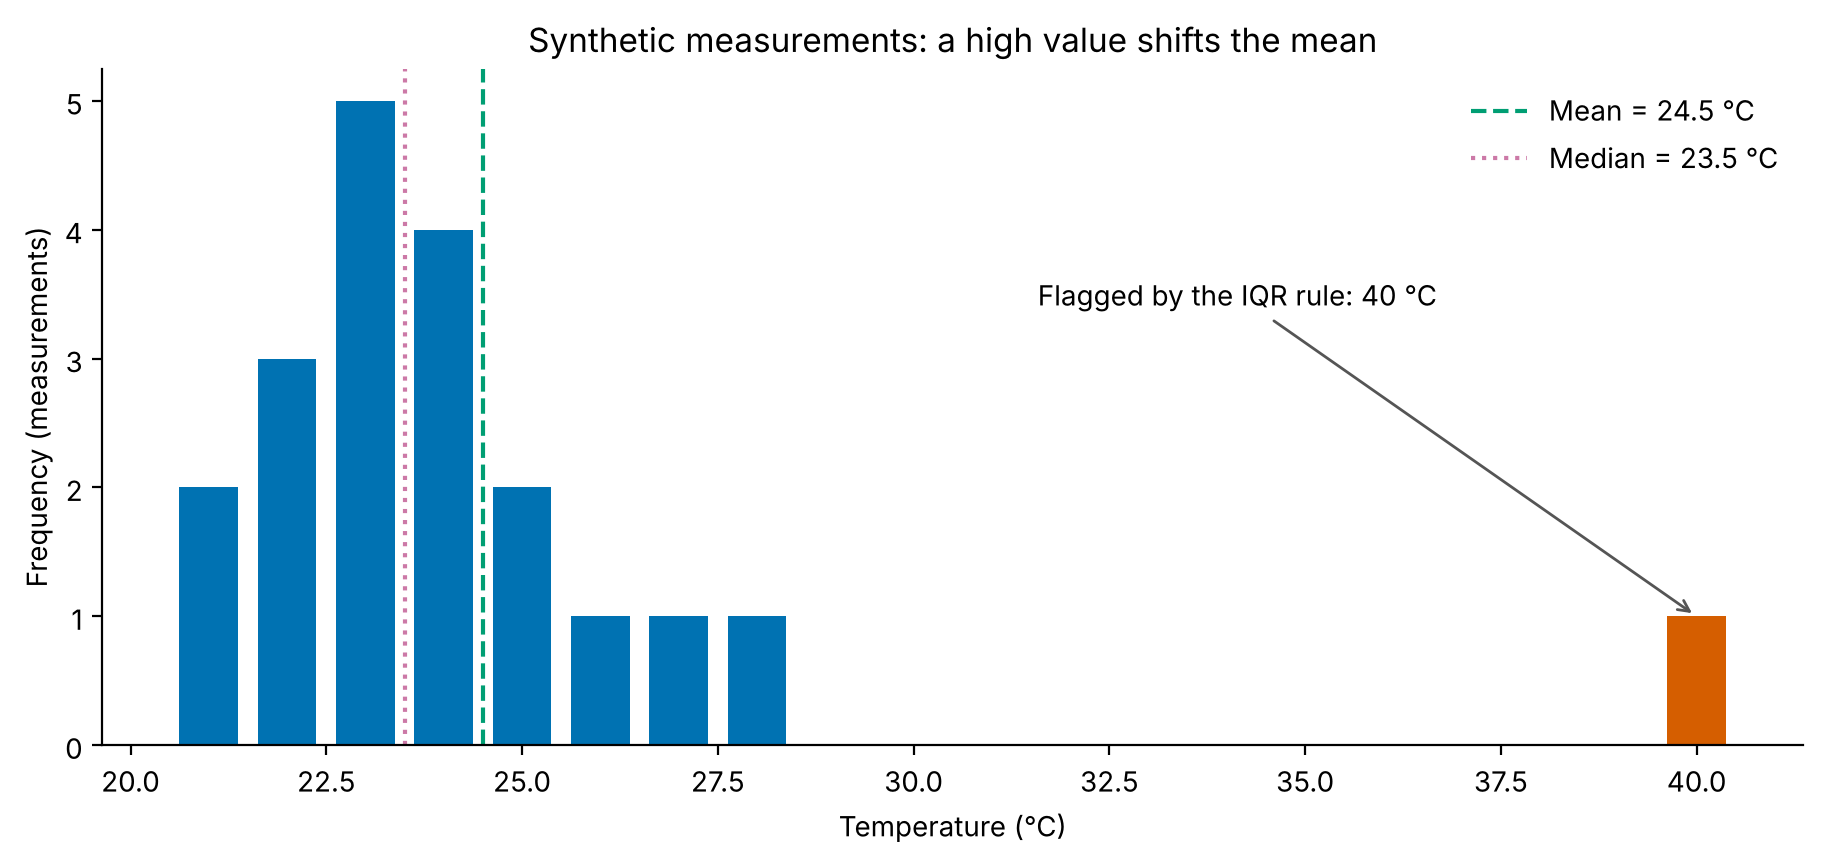

In [22]:
# Import pyplot to show the figure.
import matplotlib.pyplot as plt

# Build the figure.
distribution_figure = plot_distribution(DATA)
# Display it.
plt.show()


## 10. Extension: compute mean and variance from a stream

A stream may be too large to store, or it may only be readable once. Welford's
algorithm updates a count, mean, and sum of squared deviations as each new
measurement arrives.

With count $k$, update using

$$\delta=x_k-\bar{x}_{k-1},\qquad
\bar{x}_k=\bar{x}_{k-1}+\delta/k,$$
$$M_{2,k}=M_{2,k-1}+\delta(x_k-\bar{x}_k).$$

Finally, $s^2=M_{2,n}/(n-1)$. The method is **O(n) time and O(1) extra space**
and does not require a second traversal. It still performs floating-point
arithmetic, so it is not an exact-arithmetic guarantee for every dataset.


In [23]:
# Define Welford's one-pass algorithm for the mean and variance.
def welford_statistics(values):
    """Count, mean, sample variance from an iterable: O(n) time, O(1) space.

    No input copy, no length lookup, and no second traversal are needed.
    """
    # Number of values seen so far.
    count = 0
    # Running mean.
    mean = 0.0
    # Running sum of squared deviations from the current mean.
    m2 = 0.0
    # One value at a time; works for any iterable, even a stream.
    for value in values:
        # Count it.
        count += 1
        # Deviation from the old mean.
        delta = value - mean
        # Update the mean.
        mean += delta / count
        # Deviation from the new mean.
        delta_after_update = value - mean
        # Welford's update for the sum of squares.
        m2 += delta * delta_after_update
    # Fewer than two values: no sample variance.
    if count < 2:
        # Stop with a clear message.
        raise ValueError("Sample variance requires at least two values.")
    # Return count, mean and sample variance.
    return count, mean, m2 / (count - 1)


In [24]:
# A generator supplies one value at a time.
stream = (value for value in DATA)
# Run Welford's algorithm on the stream.
count, online_mean, online_variance = welford_statistics(stream)
# Print the count.
print("Count:", count)
# Print the mean.
print(f"Online mean:            {online_mean:.6f} °C")
# Print the sample variance.
print(f"Online sample variance: {online_variance:.6f} °C²")
# Check it against the standard library.
assert math.isclose(online_variance, statistics.variance(DATA))


Count: 20
Online mean:            24.500000 °C
Online sample variance: 16.684211 °C²


## 11. Extension: equal complexity does not mean equal numerical accuracy

The algebraically equivalent expression

$$s^2=\frac{\sum x_i^2-(\sum x_i)^2/n}{n-1}$$

subtracts two very large, nearly equal quantities when values have a large
offset and small variation. Floating-point cancellation can destroy the small
difference. Its O(n) complexity does not make it numerically reliable.

Try values near $10^{12}$. Their deviations are the same as those of
`[1, 2, 3, 4, 5]`, whose sample variance is 2.5. The inaccurate result may vary
by runtime; never repair it by silently clipping a negative variance to zero.


In [25]:
# Define the textbook shortcut formula, sum(x²) - (sum x)²/n.
def sample_variance_difference_of_squares(values):
    """O(n), but prone to cancellation. Included as a cautionary example."""
    # Number of values.
    n = len(values)
    # At least two values are needed.
    if n < 2:
        # Stop with a clear message.
        raise ValueError("Sample variance requires at least two values.")
    # Sum of the values.
    total = sum(values)
    # Sum of the squares.
    squared_total = sum(value * value for value in values)
    # Subtracting two huge, nearly equal numbers loses the small difference.
    return (squared_total - total * total / n) / (n - 1)


In [26]:
# Values near 10¹² that differ by only 1 to 5.
shifted = [1e12 + offset for offset in (1, 2, 3, 4, 5)]
# The exact answer is 2.5.
print("Reference sample variance: ", statistics.variance(shifted))
# The shortcut formula fails badly here.
print("Difference of squares:     ", sample_variance_difference_of_squares(shifted))
# The two-pass method is correct.
print("Two-pass calculation:      ", sample_variance_two_pass(shifted))
# Welford is correct too ([2] picks the variance from the tuple).
print("Welford calculation:       ", welford_statistics(iter(shifted))[2])


Reference sample variance:  2.5
Difference of squares:      0.0
Two-pass calculation:       2.5
Welford calculation:        2.5


## 12. Operation counts before stopwatch timings

The nested frequency algorithm executes exactly $n^2$ equality checks. The
dictionary algorithm makes $n$ frequency updates; each update is expected
amortized O(1), and extracting modes adds O(u) work.

The following numbers are **derived operation counts**, not measured seconds
and not a claim that an equality check costs the same as a dictionary update.


In [27]:
# Table header.
print(f"{'n':>7} {'Nested equality checks':>25} {'Dictionary updates':>22}")
# Double n each time.
for n in (10, 20, 40, 80, 160):
    # Nested scans grow as n², dictionary updates as n.
    print(f"{n:7d} {n * n:25d} {n:22d}")


      n    Nested equality checks     Dictionary updates
     10                       100                     10
     20                       400                     20
     40                      1600                     40
     80                      6400                     80
    160                     25600                    160


## 13. Timing experiment: measure implementations, not just formulas

For each input size, every algorithm receives the same seeded random integer
list. Correctness is checked before timing. Record the fastest of three runs
to reduce interference from occasional system activity. The timed calls include
input copies and output creation where the implementation performs them.

These are measurements of this runtime, these implementations, and these input
sizes—not universal timings. The dictionary and Quickselect claims are expected
complexities, not guarantees proved by this small benchmark. Random inputs also
do not demonstrate insertion sort's already-sorted best case.

**Before running:** When `n` doubles, an ideal linear model predicts roughly
twice the work, and a quadratic model roughly four times. Small-input timings
may deviate substantially because of fixed overhead and noise.


In [28]:
# Define a function that times every algorithm on random inputs of increasing size.
def benchmark_algorithms(sizes=(100, 200, 400, 800, 1600), repeats=3):
    """Measured best-of-repeats times on seeded inputs; no universal speed claim."""
    # Seeded generator, so the inputs are reproducible.
    rng = random.Random(2026)
    # Algorithms grouped by the statistic they compute.
    families = {
        "Mode": {
            "Nested scans": modes_quadratic,
            "Frequency dictionary": modes_hash,
        },
        "Median": {
            "Insertion sort": median_via_insertion,
            "Merge sort": median_via_merge,
            "Quickselect": median_via_selection,
            "Python sorted": median_via_builtin,
        },
        "Sample variance": {
            "Repeated mean": sample_variance_repeated_mean,
            "Two passes": sample_variance_two_pass,
            "Welford": lambda values: welford_statistics(values)[2],
        },
    }
    # One result row per (statistic, algorithm, size).
    measurements = []
    # For each input size ...
    for n in sizes:
        # ... make random integers between 0 and 99.
        data = [rng.randrange(100) for _ in range(n)]
        # Reference answers from the standard library.
        expected = {
            "Mode": modes_hash(data),
            "Median": statistics.median(data),
            "Sample variance": statistics.variance(data),
        }
        # For each statistic ...
        for family, algorithms in families.items():
            # ... and each algorithm for it:
            for name, function in algorithms.items():
                # Compute the answer.
                answer = function(data)
                # Modes are compared exactly ...
                if family == "Mode":
                    # Must match the reference.
                    assert answer == expected[family]
                # ... floating-point results with a tolerance.
                else:
                    # Must match the reference within the tolerance.
                    assert math.isclose(answer, expected[family], rel_tol=1e-10,
                                        abs_tol=1e-10)
                # Best time over several repeats (the minimum is least affected by other programs).
                seconds = min(timeit.repeat(
                    lambda: function(data), number=1, repeat=repeats
                ))
                # Record the measurement.
                measurements.append({"family": family, "algorithm": name,
                                     "n": n, "seconds": seconds})
    # Return all measurements.
    return measurements

# Define a function that plots the timings on log-log axes.
def plot_benchmarks(measurements):
    """Return three timing panels; the data are actual local measurements."""
    # Import inside the function (optional dependency).
    import matplotlib.pyplot as plt

    # One panel per statistic.
    families = ["Mode", "Median", "Sample variance"]
    # Colour-blind-friendly colours.
    palette = ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]
    # Three panels side by side.
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.1), constrained_layout=True)
    # For each panel and its statistic:
    for ax, family in zip(axes, families):
        # The measurements for this statistic.
        rows = [row for row in measurements if row["family"] == family]
        # Algorithm names in first-seen order, without duplicates.
        names = list(dict.fromkeys(row["algorithm"] for row in rows))
        # One line per algorithm.
        for color, name in zip(palette, names):
            # Its measurements.
            series = [row for row in rows if row["algorithm"] == name]
            # Time (ms) against n on log-log axes; the slope shows the growth rate.
            ax.loglog([row["n"] for row in series],
                      [row["seconds"] * 1000 for row in series],
                      marker="o", color=color, label=name)
        # Title and axis labels.
        ax.set(title=family, xlabel="Input size n", ylabel="Best time (ms)")
        # Faint grid.
        ax.grid(alpha=0.2)
        # Small legend without a box.
        ax.legend(frameon=False, fontsize=9)
    # Overall title.
    fig.suptitle("Measured timings on seeded random inputs (log-log axes)")
    # Return the figure.
    return fig


Measured results at n = 1600 (best of three runs):
Mode             Nested scans              49.7223 ms
Mode             Frequency dictionary       0.0679 ms
Median           Insertion sort            41.8602 ms
Median           Merge sort                 2.1210 ms
Median           Quickselect                1.2847 ms
Median           Python sorted              0.1426 ms
Sample variance  Repeated mean             57.4788 ms
Sample variance  Two passes                 0.1630 ms
Sample variance  Welford                    0.1529 ms


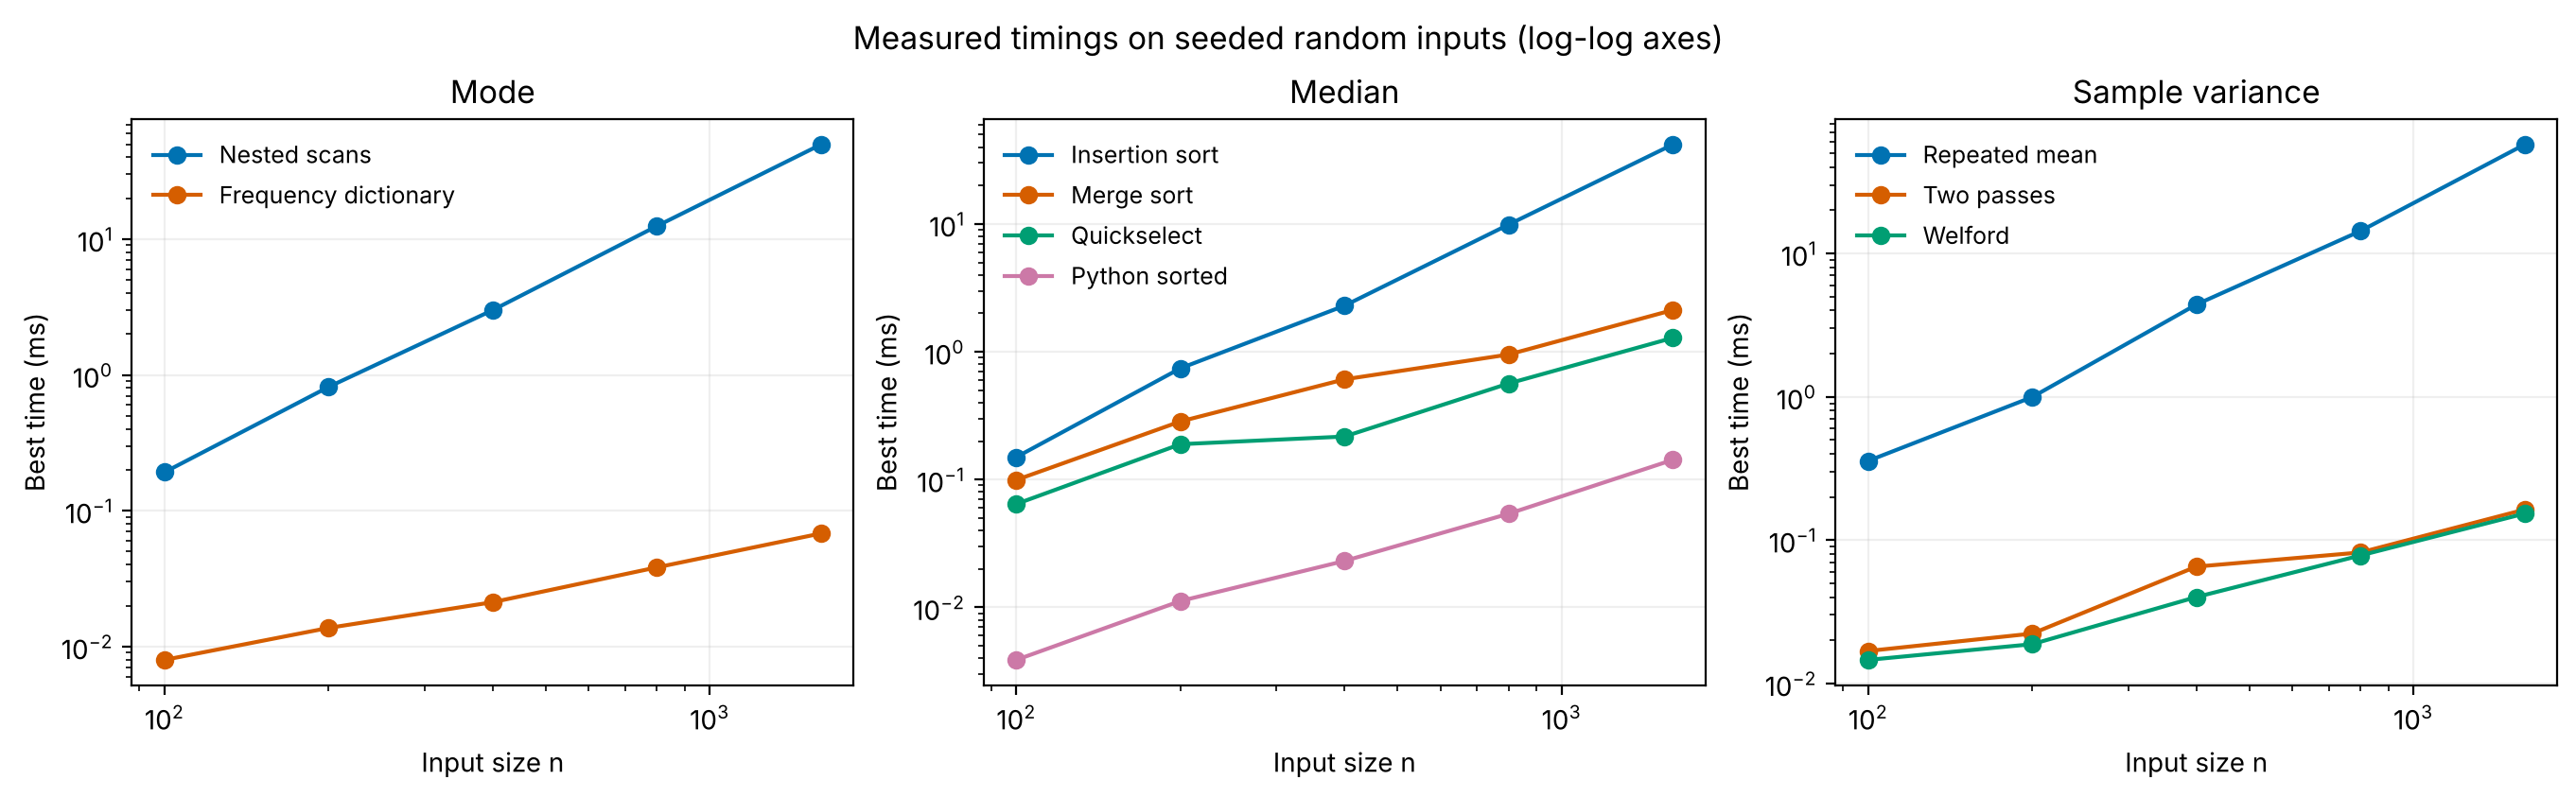

In [29]:
# Run the benchmark (a few seconds).
timings = benchmark_algorithms()
# The largest input size measured.
largest_n = max(row["n"] for row in timings)
# Heading for the table.
print(f"Measured results at n = {largest_n} (best of three runs):")
# For each measurement ...
for row in timings:
    # ... at the largest size only ...
    if row["n"] == largest_n:
        # ... print the statistic, algorithm and time.
        print(f"{row['family']:16} {row['algorithm']:22} "
              f"{row['seconds'] * 1000:10.4f} ms")

# Build the timing figure.
timing_figure = plot_benchmarks(timings)
# Display it.
plt.show()


## 14. Complexity comparison

| Task and implementation | Time | Extra space beyond input | Important condition |
|---|---|---|---|
| Read the list length or one indexed element | $O(1)$ | $O(1)$ | A Python list/tuple |
| Mean or extrema by scanning | $O(n)$ | $O(1)$ | Nonempty input |
| Sample variance, recomputing mean for every value | $O(n^2)$ | $O(1)$ | $n\ge2$ |
| Sample variance, two passes | $O(n)$ | $O(1)$ | Input can be traversed twice |
| Mean and variance with Welford | $O(n)$ | $O(1)$ | Can consume a stream |
| Mode with nested scans | $O(n^2)$ | $O(u)$ | This version stores counts |
| Mode with a frequency dictionary | Expected $O(n)$ | $O(u)$ | Normal hashing behavior |
| Median via insertion-sort copy | Average/worst $O(n^2)$; best $O(n)$ | $O(n)$ | The input copy counts |
| Median via merge-sort copy | $O(n\log n)$ | $O(n)$ | This implementation |
| Median via Python `sorted` | Worst $O(n\log n)$ | $O(n)$ | Adaptive to existing order |
| Median via randomized Quickselect | Expected $O(n)$; worst $O(n^2)$ | $O(n)$ | Input-preserving copy |
| Median or our quartiles from already sorted data | $O(1)$ | $O(1)$ | Sorting cost already paid |
| IQR flags once the fences are known | $O(n)$ | $O(f)$ output | $f$ flagged values |
| Complete summary with one shared sort | Worst $O(n\log n)$ | $O(n)$ | Reuses ordered data |
| Running means with a running total | $O(n)$ | $O(n)$ output | $O(1)$ other working space |

**Why sorting often dominates:** a fixed number of O(n) scans plus one
O(n log n) sort gives O(n log n), rather than O(n² log n).


## 15. Check the answers independently

These checks compare our algorithms with `statistics` and `sorted`, exercise
odd and even lengths, tied modes, repeated values, negative values, and multiple
pivot sequences, and confirm that the functions preserve their inputs. Empty
datasets and invalid numeric values are handled explicitly. The deliberately
unstable variance formula is not presented as a correct general implementation.


In [30]:
# Define a test function that compares every implementation with the standard library.
def run_checks():
    """Compare implementations with independent standard-library references."""
    # Seeded generator for random test cases.
    rng = random.Random(23)
    # Hand-picked edge cases: one value, ties, negatives, floats, the real data.
    cases = [[0], [5, 5, 5], [2, 1], [3, 1, 2],
             [-3, -1, -2, -1], [0.5, -1.5, 0.5, 2.0], DATA]
    # Add random cases of several sizes ...
    for size in (1, 2, 3, 4, 5, 10, 31):
        # ... three for each size.
        cases.extend([[rng.randrange(-10, 11) for _ in range(size)]
                      for _ in range(3)])
    # Count of quickselect checks.
    selection_checks = 0
    # For every test case:
    for values in cases:
        # Keep a copy to check that nothing modifies the input.
        original = values.copy()
        # The reference sorted order.
        ordered = sorted(values)
        # Insertion sort must match.
        assert insertion_sort(values) == ordered
        # Merge sort must match.
        assert merge_sort(values) == ordered
        # Every median method ...
        for function in (median_via_insertion, median_via_merge,
                         median_via_builtin, median_via_selection):
            # ... must match statistics.median.
            assert function(values) == statistics.median(values)
        # Every position k in the sorted order ...
        for k, expected in enumerate(ordered):
            # ... with three different pivot seeds ...
            for seed in (0, 1, 23):
                # ... quickselect must find the right value.
                assert quickselect(values, k, seed=seed) == expected
                # Count the check.
                selection_checks += 1
        # Fast and slow mode finders must agree ...
        assert modes_hash(values) == modes_quadratic(values)
        # ... and match statistics.multimode.
        assert modes_hash(values)[0] == statistics.multimode(values)
        # Extrema must match min and max.
        assert extrema_one_pass(values) == (min(values), max(values))
        # The mean must match statistics.mean.
        assert math.isclose(mean_one_pass(values), statistics.mean(values),
                            rel_tol=1e-12, abs_tol=1e-12)
        # Variance checks need at least two values.
        if len(values) >= 2:
            # The reference variance.
            expected = statistics.variance(values)
            # Both variance methods ...
            for function in (sample_variance_two_pass,
                             sample_variance_repeated_mean):
                # ... must match it.
                assert math.isclose(function(values), expected,
                                    rel_tol=1e-10, abs_tol=1e-10)
            # Welford's results.
            count, mean, variance = welford_statistics(iter(values))
            # Its count must be right.
            assert count == len(values)
            # Its mean must match.
            assert math.isclose(mean, statistics.mean(values),
                                rel_tol=1e-10, abs_tol=1e-10)
            # Its variance must match.
            assert math.isclose(variance, expected, rel_tol=1e-10, abs_tol=1e-10)
        # No algorithm may change its input.
        assert values == original, "An algorithm unexpectedly changed the input."
    # Sorting an empty list gives an empty list.
    assert insertion_sort([]) == merge_sort([]) == []
    # Known quartiles for the data.
    assert quartiles_from_sorted(sorted(DATA)) == (22.5, 25.0)
    # Known quartiles for 1..5.
    assert quartiles_from_sorted([1, 2, 3, 4, 5]) == (1.5, 4.5)
    # Only 40 is flagged.
    assert analyze_measurements(DATA)["flagged_values"] == [40]
    # Invalid inputs: empty, NaN, infinity, a bool, a string.
    for bad in ([], [1, float("nan")], [1, float("inf")], [True, 2], ["1", 2]):
        # Try validating each one ...
        try:
            # ... which should raise an exception.
            validate_measurements(bad)
        # The expected exceptions ...
        except (ValueError, TypeError):
            # ... are fine.
            pass
        # No exception at all ...
        else:
            # ... means the check failed.
            raise AssertionError("Invalid data were accepted.")
    # Every statistic that is undefined for empty data ...
    for function in (mean_one_pass, extrema_one_pass, modes_hash,
                     modes_quadratic, median_via_insertion, median_via_merge,
                     median_via_builtin, median_via_selection):
        # ... must refuse an empty list:
        try:
            # Call it with no data.
            function([])
        # The expected exception ...
        except ValueError:
            # ... is fine.
            pass
        # No exception ...
        else:
            # ... means the check failed.
            raise AssertionError("An undefined empty-data statistic was accepted.")
    # The cancellation example from earlier.
    shifted = [1e12 + offset for offset in (1, 2, 3, 4, 5)]
    # The two-pass method must give exactly 2.5.
    assert sample_variance_two_pass(shifted) == 2.5
    # So must Welford.
    assert welford_statistics(iter(shifted))[2] == 2.5
    # Summary of what was checked.
    return {"datasets_checked": len(cases), "order_statistic_checks": selection_checks,
            "status": "passed"}


In [31]:
# Run all the checks; any failure stops with an AssertionError.
checks = run_checks()
# Print the summary.
print(checks)


{'datasets_checked': 28, 'order_statistic_checks': 615, 'status': 'passed'}


## 16. Student exercises

1. **Prediction:** Replace the last value with 80. Predict which changes more,
   the mean or median. Run the analysis and explain the result.
2. **Exact work:** Instrument `modes_quadratic` to count its equality checks.
   Confirm the n² count for lengths 10, 20, and 40.
3. **Hidden loop:** Rewrite mode counting using `values.count(candidate)`.
   Explain why removing a visible inner loop does not change its complexity.
4. **Best case:** Time insertion sort on sorted, reverse-sorted, and random
   data. Relate the result to the number of shifts.
5. **Memory tradeoff:** Modify insertion sort to operate on the supplied list
   directly. Explain which copy disappears and what changes for the caller.
6. **Population versus sample:** Add population variance to the summary and
   explain the denominator and units.
7. **Streaming:** Read one measurement at a time into Welford's algorithm.
   Why can a stream supply mean and variance without being stored, while our
   exact median implementations still retain or copy values?
8. **Reuse:** Explain why sorting once for the median and quartiles is clearer
   than repeating a sort for each statistic. Does avoiding three sorts change
   the asymptotic class, or mainly the constant factor?
9. **Running mean:** Compare the running-total method with
   `sum(values[:i]) / i` for every prefix. Include slicing in the analysis.
10. **Selection:** For an even-length list, explain why averaging two selected
    middle values still has expected O(n) time in this implementation.

### Discussion notes

- A statistic is a target answer; an algorithm is a procedure for obtaining it.
- Sequential scans add their costs; nested scans multiply their iteration counts.
- Timing a built-in against Python loops also measures implementation overhead.
- Two linear-time formulas can differ greatly in floating-point accuracy.
- A flagged value needs context before any scientific decision to exclude it.
- Core work: sections 1–6, 8–9, and 12–16. Use sections 7 and 10–11 as extensions.
